# 03 · Features and Modelling

**Longevity Hook Lab, Part A**: *What makes a YouTube Short beat its channel's median views?*

Input: `data/shorts.csv` (2,740 Shorts, 11 channels, label `beat` from notebook 01).
Feature code lives in `codes/features.py` so Part B (the title rewriter) builds features in exactly the same way.

Plan:
1. Build features and look at beat-rate by hook style, topic and claim intensity.
2. Majority baseline → logistic regression → random forest (5-fold CV + small grid search).
3. Test-set metrics (ROC-AUC, ROC curve, confusion matrix, precision/recall) and AUC by creator.
4. Interpret coefficients / importances and save the best pipeline.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

from features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, TEXT_FEATURE, add_features, build_preprocessor

DATA = Path("../data")
ASSETS = Path("../images")
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)
RANDOM_STATE = 42

ACCENT = "#2a78d6"   # single-series colour
SECOND = "#e07b39"   # second series (random forest)
REF = "#8a8984"      # reference line
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})

shorts = add_features(pd.read_csv(DATA / "shorts.csv"))
BASE_RATE = shorts["beat"].mean()
print(shorts.shape, "overall beat-rate:", round(BASE_RATE, 3))

(2740, 30) overall beat-rate: 0.48


## 1. Features

| Group | Columns | How |
|---|---|---|
| Title structure | `char_count`, `word_count`, `has_question`, `has_number`, `has_you`, `has_emoji`, `caps_ratio`, `hashtag_count`, `has_person_name` | simple counts / regex |
| Hook style | `hook_style`: how_to / list / question / warning / story / other | keyword rules, first match wins |
| Topic | `topic`: sleep / diet_fasting / supplements / brain / exercise / aging / other | keyword rules, first match wins |
| Claim intensity | `claim_intensity` | number of hype words (cure, secret, never, best, hack, ...) |
| Timing / format | `publish_hour`, `publish_weekday` (UTC, as categories), `duration_sec` + `duration_bucket` | the EDA showed duration is U-shaped, so a bucket helps the linear model |
| Text | `title_clean` → TF-IDF (≤ 500 terms, 1–2 word phrases) | person names removed so the model learns words, not guests |

Not used: `likes`, `comments`, `views` (post-publish leakage), `age_days` (handled by the label), `creator` / `channel_type`.

In [2]:
shorts[["title", "hook_style", "topic", "claim_intensity", "has_person_name", "title_clean"]].sample(8, random_state=RANDOM_STATE)

,title,hook_style,topic,claim_intensity,has_person_name,title_clean
365,men take notes,other,other,0,0,men take notes
393,What Creatine May Offer Beyond Fitness,question,supplements,0,0,What Creatine May Offer Beyond Fitness
1293,77% OF YOUNG AMERICANS AREN'T FIT TO SERVE wit...,list,aging,0,1,77% OF YOUNG AMERICANS AREN'T FIT TO SERVE Chr...
1350,HEALTHMAXXING 101,other,other,0,0,HEALTHMAXXING 101
2103,Stop ignoring these hidden nutrient gaps ⚠️ #h...,warning,other,1,0,Stop ignoring these hidden nutrient gaps ⚠️ #h...
2271,Your Grip Strength Could Predict Your Lifespan,other,exercise,0,0,Your Grip Strength Could Predict Your Lifespan
2348,How One Exercise Restored Independence for a 7...,question,exercise,0,1,How One Exercise Restored Independence for a 7...
2233,Cognitive Behavioral Therapy: A Beginner’s Gui...,other,brain,0,1,Cognitive Behavioral Therapy: A Beginner’s Guide


In [3]:
for col in ["hook_style", "topic", "claim_intensity", "duration_bucket"]:
    print(shorts[col].value_counts().to_dict())

{'other': 1261, 'question': 847, 'warning': 225, 'story': 167, 'how_to': 135, 'list': 105}
{'other': 1359, 'diet_fasting': 590, 'exercise': 221, 'brain': 213, 'supplements': 142, 'aging': 109, 'sleep': 106}
{0: 2342, 1: 339, 2: 57, 3: 2}
{'31–60s': 1385, '61–90s': 670, '≤30s': 368, '91s+': 317}


## 2. EDA on the new features

Same chart style as notebook 02: bar = beat-rate in the group, whisker = 95% interval, dashed line = overall beat-rate. Groups with fewer than 20 Shorts are hidden.

In [4]:
def beat_rate_chart(df, column, title, order=None, xlabel=None, min_n=20, filename=None):
    """Bar chart of beat-rate per group, with 95% CI and n under each bar."""
    stats = df.groupby(column, observed=True)["beat"].agg(["mean", "size"])
    stats = stats[stats["size"] >= min_n]
    if order is not None:
        stats = stats.reindex([o for o in order if o in stats.index])
    ci = 1.96 * np.sqrt(stats["mean"] * (1 - stats["mean"]) / stats["size"])

    fig, ax = plt.subplots(figsize=(max(5, 0.75 * len(stats) + 2), 4))
    x = np.arange(len(stats))
    ax.bar(x, stats["mean"], width=0.6, color=ACCENT)
    ax.errorbar(x, stats["mean"], yerr=ci, fmt="none", ecolor="#3a3a38", elinewidth=1, capsize=3)
    ax.axhline(BASE_RATE, color=REF, linestyle="--", linewidth=1.5)
    ax.set_xticks(x, [f"{i}\nn={n}" for i, n in zip(stats.index, stats["size"])], fontsize=9)
    ax.set_ylim(0.2, 0.8)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylabel("Beat-rate")
    ax.set_xlabel(xlabel or "")
    ax.set_title(title, loc="left", fontweight="bold")
    plt.tight_layout()
    if filename:
        fig.savefig(ASSETS / filename, dpi=150)
    plt.show()
    return stats.assign(ci=ci).round(3)

### 2.1 Which hook styles win?

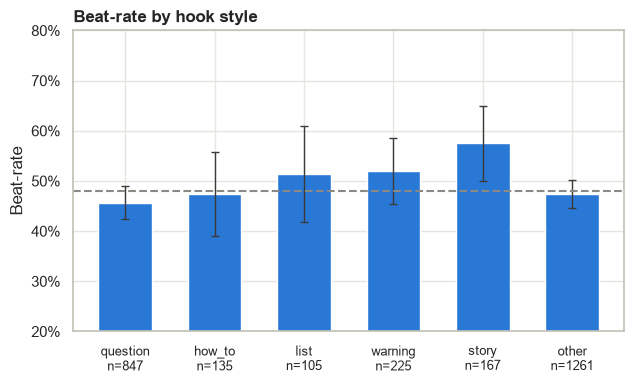

,mean,size,ci
hook_style,,,
question,0.457,847,0.034
how_to,0.474,135,0.084
list,0.514,105,0.096
warning,0.520,225,0.065
story,0.575,167,0.075
other,0.474,1261,0.028


In [5]:
beat_rate_chart(shorts, "hook_style", "Beat-rate by hook style",
                order=["question", "how_to", "list", "warning", "story", "other"],
                filename="beat_rate_hook_style.png")

### 2.2 Which topics win?

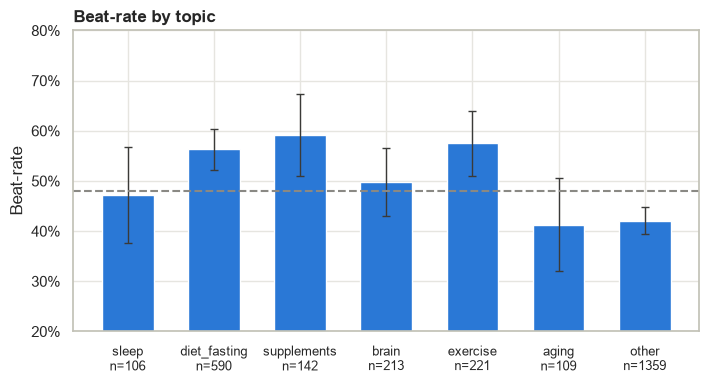

,mean,size,ci
topic,,,
sleep,0.472,106,0.095
diet_fasting,0.563,590,0.040
supplements,0.592,142,0.081
brain,0.498,213,0.067
exercise,0.575,221,0.065
aging,0.413,109,0.092
other,0.421,1359,0.026


In [6]:
beat_rate_chart(shorts, "topic", "Beat-rate by topic",
                order=["sleep", "diet_fasting", "supplements", "brain", "exercise", "aging", "other"],
                filename="beat_rate_topic.png")

### 2.3 Does hype help or hurt?

`claim_intensity` is capped at 2 for the chart (only a handful of titles have 3+).

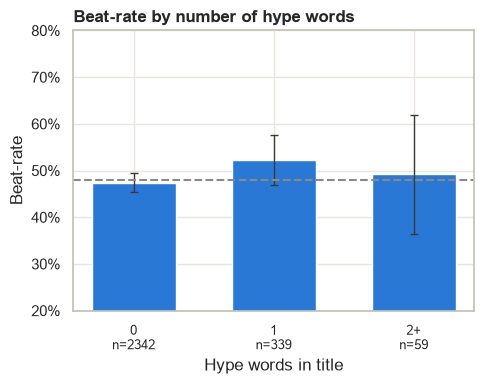

,mean,size,ci
hype,,,
0,0.474,2342,0.020
1,0.522,339,0.053
2+,0.492,59,0.128


In [7]:
shorts["hype"] = shorts["claim_intensity"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
beat_rate_chart(shorts, "hype", "Beat-rate by number of hype words", order=["0", "1", "2+"],
                xlabel="Hype words in title", filename="beat_rate_hype.png")

**Within each creator.** Creators differ in how much hype they use, so the overall chart could just be comparing creators. Below: each creator's beat-rate for titles *with* vs *without* hype words. Points right of the diagonal mean hype helped for that creator.

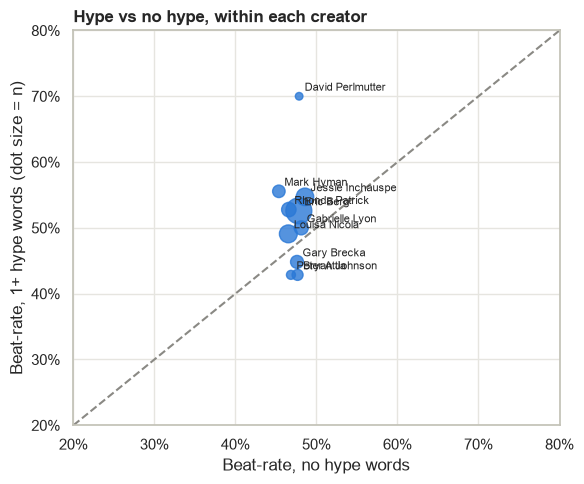

,rate_hype,rate_no_hype,n_hype,n_no_hype,diff_pts
creator,,,,,
Bryan Johnson,0.43,0.48,21,279,-4.8
Peter Attia,0.43,0.47,14,286,-4.0
Gary Brecka,0.45,0.48,29,271,-2.8
Gabrielle Lyon,0.50,0.48,34,266,1.9
Louisa Nicola,0.49,0.47,55,245,2.6
Eric Berg,0.53,0.48,116,184,4.8
Jessie Inchauspe,0.55,0.49,53,247,6.1
Rhonda Patrick,0.53,0.47,36,264,6.2
Mark Hyman,0.56,0.45,27,97,10.2


In [8]:
shorts["has_hype"] = (shorts["claim_intensity"] > 0).map({True: "hype", False: "no_hype"})
within = (shorts.pivot_table(index="creator", columns="has_hype", values="beat", aggfunc=["mean", "size"])
          .droplevel(0, axis=1).set_axis(["rate_hype", "rate_no_hype", "n_hype", "n_no_hype"], axis=1))
within["diff_pts"] = ((within["rate_hype"] - within["rate_no_hype"]) * 100).round(1)
within = within.sort_values("diff_pts")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(within["rate_no_hype"], within["rate_hype"], s=within["n_hype"] * 3, color=ACCENT, alpha=0.8)
for name, row in within.iterrows():
    ax.annotate(name, (row["rate_no_hype"], row["rate_hype"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.plot([0.2, 0.8], [0.2, 0.8], color=REF, linestyle="--", linewidth=1.5)
ax.set_xlim(0.2, 0.8); ax.set_ylim(0.2, 0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Beat-rate, no hype words")
ax.set_ylabel("Beat-rate, 1+ hype words (dot size = n)")
ax.set_title("Hype vs no hype, within each creator", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(ASSETS / "hype_within_creator.png", dpi=150)
plt.show()
within.round(2)

In [9]:
print("Creators where hype titles beat more often:", (within["diff_pts"] > 0).sum(), "of", len(within))

Creators where hype titles beat more often: 8 of 11


## 3. Train/test split

Stratified 80/20 split so both sets keep the ~48% beat-rate. The test set is only used once, in section 6.

In [10]:
X = shorts[NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TEXT_FEATURE]]
y = shorts["beat"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape, "| beat-rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

train: (2192, 17) test: (548, 17) | beat-rate train/test: 0.48 0.48


## 4. Baseline: always predict the majority class

In [11]:
baseline = DummyClassifier(strategy="most_frequent")
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="roc_auc")
print("Baseline CV ROC-AUC:", baseline_cv.mean().round(3), "| accuracy:", round(1 - y_train.mean(), 3))

Baseline CV ROC-AUC: 0.5 | accuracy: 0.52


## 5. Models

Both models share the same preprocessing (`build_preprocessor()`): scale the numeric columns, one-hot the categories, TF-IDF the cleaned title.

### 5.1 Logistic regression

In [12]:
lr_pipe = Pipeline([
    ("pre", build_preprocessor()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
lr_cv = cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("LR default CV ROC-AUC:", lr_cv.mean().round(3), "±", lr_cv.std().round(3))

lr_grid = GridSearchCV(lr_pipe, {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}, cv=cv, scoring="roc_auc", n_jobs=-1)
lr_grid.fit(X_train, y_train)
print("Best C:", lr_grid.best_params_["model__C"], "| CV ROC-AUC:", round(lr_grid.best_score_, 3))

LR default CV ROC-AUC: 0.569 ± 0.023


Best C: 0.03 | CV ROC-AUC: 0.586


### 5.2 Random forest

In [13]:
rf_pipe = Pipeline([
    ("pre", build_preprocessor()),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_cv = cross_val_score(rf_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("RF default CV ROC-AUC:", rf_cv.mean().round(3), "±", rf_cv.std().round(3))

rf_params = {"model__n_estimators": [300, 600], "model__max_depth": [6, 12, None], "model__min_samples_leaf": [1, 5]}
rf_grid = GridSearchCV(rf_pipe, rf_params, cv=cv, scoring="roc_auc", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best params:", rf_grid.best_params_, "| CV ROC-AUC:", round(rf_grid.best_score_, 3))

RF default CV ROC-AUC: 0.603 ± 0.018


Best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 600} | CV ROC-AUC: 0.606


### 5.3 Cross-validation summary

In [14]:
cv_summary = pd.DataFrame({
    "model": ["Majority baseline", "Logistic regression (tuned)", "Random forest (tuned)"],
    "cv_roc_auc": [baseline_cv.mean(), lr_grid.best_score_, rf_grid.best_score_],
}).round(3)
cv_summary

,model,cv_roc_auc
0,Majority baseline,0.500
1,Logistic regression (tuned),0.586
2,Random forest (tuned),0.606


## 6. Test-set results

The model with the higher **CV** AUC is picked as the final model *before* looking at the test set; both are shown for comparison.

In [15]:
models = {"Logistic regression": lr_grid.best_estimator_, "Random forest": rf_grid.best_estimator_}
best_name = "Logistic regression" if lr_grid.best_score_ >= rf_grid.best_score_ else "Random forest"
best_model = models[best_name]

test_auc = {name: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for name, m in models.items()}
print("Chosen by CV:", best_name)
print({k: round(v, 3) for k, v in test_auc.items()})

Chosen by CV: Random forest
{'Logistic regression': 0.588, 'Random forest': 0.603}


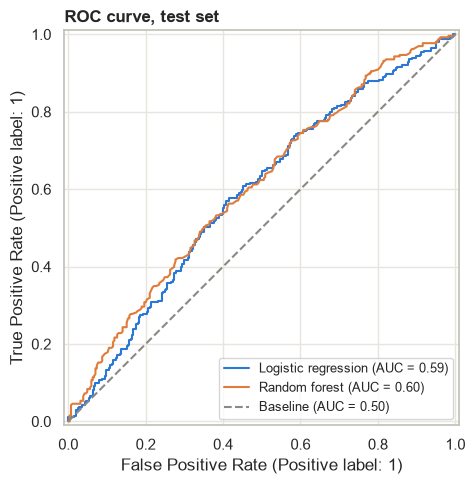

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, m), color in zip(models.items(), [ACCENT, SECOND]):
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name, curve_kwargs={"color": color})
ax.plot([0, 1], [0, 1], color=REF, linestyle="--", linewidth=1.5, label="Baseline (AUC = 0.50)")
ax.set_title("ROC curve, test set", loc="left", fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
fig.savefig(ASSETS / "roc_curve.png", dpi=150)
plt.show()

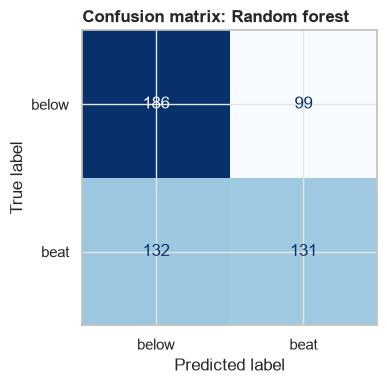

              precision    recall  f1-score   support

       below      0.585     0.653     0.617       285
        beat      0.570     0.498     0.531       263

    accuracy                          0.578       548
   macro avg      0.577     0.575     0.574       548
weighted avg      0.578     0.578     0.576       548



In [17]:
y_pred = best_model.predict(X_test)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["below", "beat"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(ASSETS / "confusion_matrix.png", dpi=150)
plt.show()
print(classification_report(y_test, y_pred, target_names=["below", "beat"], digits=3))

## 7. AUC by creator (a check, not a feature)

Does the model work across channels or only for a few? Creators with few test Shorts have noisy AUCs, so `n_test` is shown.

In [18]:
test_scored = shorts.loc[X_test.index, ["creator", "beat"]].assign(p_beat=best_model.predict_proba(X_test)[:, 1])
auc_by_creator = (test_scored.groupby("creator")
                  .apply(lambda g: pd.Series({"n_test": len(g), "roc_auc": roc_auc_score(g["beat"], g["p_beat"])}),
                         include_groups=False)
                  .sort_values("roc_auc"))
auc_by_creator["n_test"] = auc_by_creator["n_test"].astype(int)
auc_by_creator.round(3)

,n_test,roc_auc
creator,,
David Perlmutter,28,0.431
Eric Berg,59,0.480
Mark Hyman,24,0.511
Andrew Huberman,22,0.542
Jessie Inchauspe,68,0.586
Louisa Nicola,62,0.607
Bryan Johnson,44,0.621
Gabrielle Lyon,54,0.637
Rhonda Patrick,70,0.665


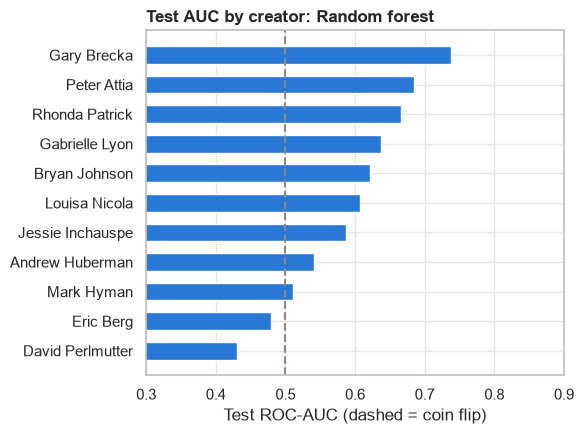

In [19]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(auc_by_creator.index, auc_by_creator["roc_auc"], color=ACCENT, height=0.6)
ax.axvline(0.5, color=REF, linestyle="--", linewidth=1.5)
ax.set_xlim(0.3, 0.9)
ax.set_xlabel("Test ROC-AUC (dashed = coin flip)")
ax.set_title(f"Test AUC by creator: {best_name}", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(ASSETS / "auc_by_creator.png", dpi=150)
plt.show()

## 8. Interpretation

### 8.1 Logistic regression coefficients

Coefficients are on scaled / one-hot / TF-IDF inputs, so compare direction and rough size, not exact units. Positive = more likely to beat the neighbours' median.

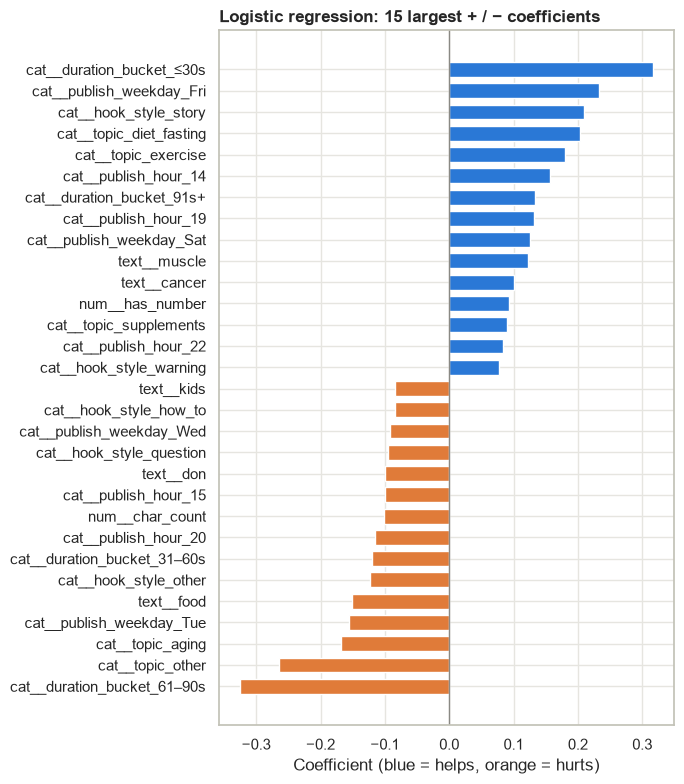

In [20]:
lr_best = lr_grid.best_estimator_
coefs = pd.Series(lr_best.named_steps["model"].coef_[0],
                  index=lr_best.named_steps["pre"].get_feature_names_out()).sort_values()
top = pd.concat([coefs.head(15), coefs.tail(15)])

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top.index, top.values, color=[SECOND if v < 0 else ACCENT for v in top.values], height=0.7)
ax.axvline(0, color=REF, linewidth=1)
ax.set_xlabel("Coefficient (blue = helps, orange = hurts)")
ax.set_title("Logistic regression: 15 largest + / − coefficients", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(ASSETS / "lr_coefficients.png", dpi=150)
plt.show()

In [21]:
# The hand-built features only (no TF-IDF words), easier to talk about
hand_built = coefs[~coefs.index.str.startswith("text__")].sort_values(ascending=False)
pd.concat([hand_built.head(10), hand_built.tail(10)]).round(3).to_frame("coef")

,coef
cat__duration_bucket_≤30s,0.317
cat__publish_weekday_Fri,0.232
cat__hook_style_story,0.209
cat__topic_diet_fasting,0.203
cat__topic_exercise,0.180
cat__publish_hour_14,0.157
cat__duration_bucket_91s+,0.134
cat__publish_hour_19,0.131
cat__publish_weekday_Sat,0.126
num__has_number,0.093


### 8.2 Random forest feature importances

Impurity-based importance: shows *how much* a feature is used, not the direction. It favours continuous columns (like `duration_sec`, `char_count`), so read alongside the coefficients.

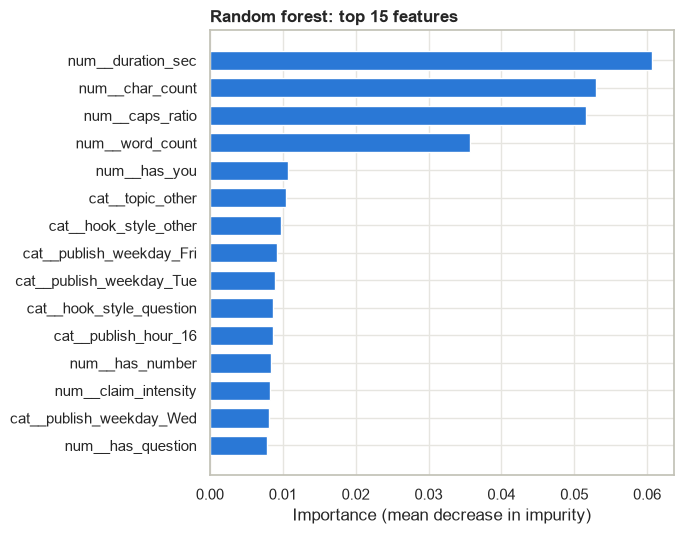

In [22]:
rf_best = rf_grid.best_estimator_
importances = pd.Series(rf_best.named_steps["model"].feature_importances_,
                        index=rf_best.named_steps["pre"].get_feature_names_out()).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(importances.index, importances.values, color=ACCENT, height=0.7)
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_title("Random forest: top 15 features", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(ASSETS / "rf_importances.png", dpi=150)
plt.show()

## 9. Save the final pipeline

The saved pipeline expects the output of `add_features()` (from `codes/features.py`). Part B loads it like this:

```python
model = joblib.load("models/hook_model.joblib")
p_beat = model.predict_proba(add_features(df))[:, 1]
```

It's refit on **all** 2,740 Shorts (train + test) with the tuned settings, since the test set has already done its job.

In [23]:
final_model = (lr_grid if best_name == "Logistic regression" else rf_grid).best_estimator_
final_model.fit(X, y)
joblib.dump(final_model, MODELS / "hook_model.joblib", compress=3)   # compressed: ~18 MB instead of ~90 MB
print("Saved", best_name, "to", MODELS / "hook_model.joblib")

Saved Random forest to ../models/hook_model.joblib


## 10. Takeaways

**Performance**
- Tuned random forest: CV ROC-AUC **0.606**, test **0.603**. Logistic regression: 0.586 / 0.588. Majority baseline: 0.50. This is inside the 0.58–0.65 range expected at the start: titles and timing carry a real but modest signal.
- Test accuracy 58%; the model finds about half the Shorts that beat (recall 0.50) and is right 57% of the time when it says "beat".
- It works for most creators (8 of 11 above 0.55; best Gary Brecka 0.74, Peter Attia 0.68) but not for David Perlmutter (0.43), Eric Berg (0.48) or Mark Hyman (0.51). Those test sets are small (24–59 Shorts), so these are noisy.

**Presentation questions**
- **Which hook styles win?** Story titles (57%) and warnings (52%) beat more often than the 48% average; questions are slightly below (46%, small negative LR coefficient). Intervals overlap, so this is a lean, not a rule.
- **Which topics win?** Concrete, practical topics do best: supplements 59%, exercise 57%, diet/fasting 56%. Aging (41%) and titles with no clear topic (42%) do worst. This is the clearest title-level finding.
- **Does hype help or hurt?** Slightly helps on average (1 hype word: 52% vs 47% without), and 8 of 11 creators lean the same way. But most creators have few hype titles (Huberman only 3), so the evidence is weak. Part B still bans hype words, for responsible-AI reasons rather than performance.
- **Duration is still the strongest signal**: ≤ 30 s is the largest positive LR coefficient, 61–90 s the largest negative, and `duration_sec` is the top random-forest feature.

**For Part B**
- Saved model: tuned random forest, refit on all 2,740 Shorts → `models/hook_model.joblib`.
- A rewrite can only change title features (topic words, hook style, length, caps, numbers, "you"). Duration and posting time should be held at the draft's values when scoring.
- The forest leans on `char_count` and `caps_ratio`, so a rewriter could "win" by changing length or shouting in caps. The ≤ 70-character and no-new-claims guardrails matter, and a higher model score is not proof of more views.